In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# IMPORT
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import re # Serve per leggere i numeri con le espressioni regolari

root_path = "/content/drive/MyDrive/Action Recognition on UCF101"
src_path = os.path.join(root_path, "src")
split_path = os.path.join(root_path, "ucfTrainTestlist")

if src_path not in sys.path:
    sys.path.append(src_path)

#from dataset import UCF101Dataset
#from dataset import get_datasets
from dataset2 import UCF101DatasetFast
from dataset2 import get_datasets
from models import ResNet2D_Baseline, CustomCNN
from training import train_one_epoch, validate, get_next_run_id

In [11]:
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")

In [12]:
zip_path_drive = "/content/drive/MyDrive/Action Recognition on UCF101/UCF-101-JPG-zipped.zip"
local_root = "/content/data"
final_data_path = os.path.join(local_root, "temp_jpg_224")
if not os.path.exists(final_data_path):

    os.makedirs(local_root, exist_ok=True)

    !unzip -q -o "{zip_path_drive}" -d "{local_root}"

    print(f"Done! Data ready in: {final_data_path}")
else:
    print(f"Data already in {final_data_path}.")

# VERIFY
if os.path.exists(final_data_path):
    num_classes = len(os.listdir(final_data_path))
    print(f"Found {num_classes} classes in {final_data_path}")
else:
    print("Something gone wrong. Check zip name or path.")

Data already in /content/data/temp_jpg_224.
Found 101 classes in /content/data/temp_jpg_224


In [16]:
# HYPERPARAMETERS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
NUM_CLASSES = 101
FRAMES = 16

print(f"Using device: {DEVICE}")

Using device: cuda


In [17]:
data_root="/content/data/temp_jpg_224"
annotation_file_train=os.path.join(split_path, "trainlist01.txt")
annotation_file_test=os.path.join(split_path, "testlist01.txt")
class_ind_file=os.path.join(split_path, "classInd.txt")
config = {
    "DATA_ROOT" : data_root,
    "TRAIN_ANNOTATION_FILE": annotation_file_train,
    "TEST_ANNOTATION_FILE" : annotation_file_test,
    "CLASS_IND_FILE": class_ind_file,
    "FRAMES_PER_CLIP":16,
    "RESIZE_HEIGHT" : 224,
    "RESIZE_WIDTH" : 224
}
print("Loading Datasets...")
train_dataset, val_dataset, test_dataset = get_datasets(config)

Loading Datasets...
--------------------------------------------------
GROUP-BASED SPLIT SUMMARY:
Train samples: 7675
Val samples:   1862
Test samples:  3783
--------------------------------------------------
SUCCESS: No overlapping samples found between datasets.
--------------------------------------------------


In [18]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2) # Shuffle False per Val
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

 EXPERIMENT STARTED: CustomCNN_baseline
 AUTO-ASSIGNED ID:   Run_12
 OUTPUT FOLDER:      /content/drive/MyDrive/Action Recognition on UCF101/experiments/CustomCNN_baseline/Run_12
Initializing Model...

Starting Training loop for 50 epochs...
Stop condition: No validation loss improvement (delta=0.001) for 10 epochs.

Epoch 1/50


Validation: 100%|██████████| 117/117 [00:29<00:00,  4.00it/s]


 -> Train Loss: 4.2225 | Acc: 5.46%
 -> Val Loss:   4.0472 | Acc: 7.47%
    >>> New Best Validation Accuracy! Model saved.
Epoch 2/50


Validation: 100%|██████████| 117/117 [00:29<00:00,  4.01it/s]


 -> Train Loss: 3.7905 | Acc: 10.58%
 -> Val Loss:   3.8157 | Acc: 13.80%
    >>> New Best Validation Accuracy! Model saved.
Epoch 3/50


Validation: 100%|██████████| 117/117 [00:29<00:00,  3.93it/s]


... (39 outputs left out)

Validation: 100%|██████████| 117/117 [00:28<00:00,  4.05it/s]


 -> Train Loss: 1.7641 | Acc: 49.25%
 -> Val Loss:   3.7203 | Acc: 27.18%
!!! No improvement. Patience: 9/10
Epoch 24/50


Validation: 100%|██████████| 117/117 [00:30<00:00,  3.82it/s]


 -> Train Loss: 1.7306 | Acc: 50.64%
 -> Val Loss:   4.0463 | Acc: 25.08%
!!! No improvement. Patience: 10/10

EARLY STOPPING TRIGGERED.
   Stopping training to prevent overfitting.

 TRAINING COMPLETE
Generating training plots...


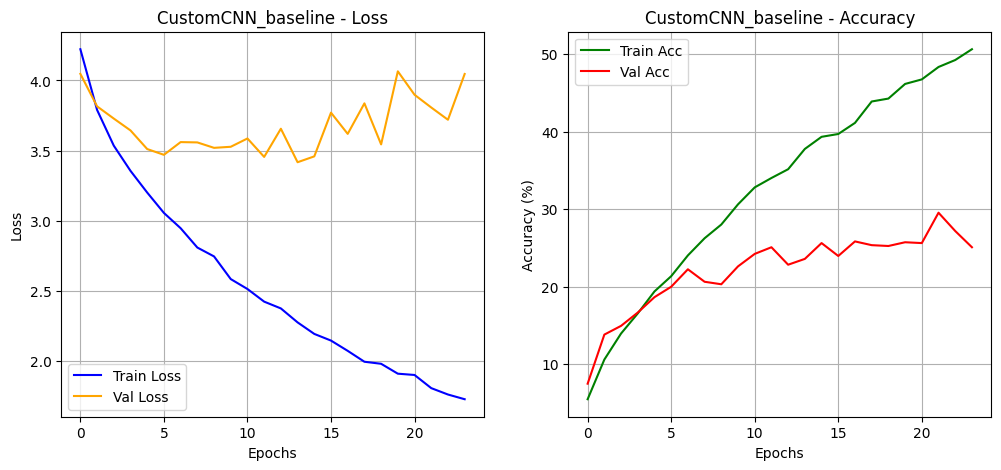

In [19]:
import matplotlib.pyplot as plt


VARIANT_NAME = "CustomCNN_baseline"
EXPERIMENTS_ROOT = os.path.join(root_path, "experiments", VARIANT_NAME)

# CONFIGURATION FOLDER
RUN_ID = get_next_run_id(EXPERIMENTS_ROOT)
checkpoint_dir = os.path.join(EXPERIMENTS_ROOT, RUN_ID)
best_model_path = os.path.join(checkpoint_dir, "best_model.pth")
plot_path = os.path.join(checkpoint_dir, "training_curves.png")

os.makedirs(checkpoint_dir, exist_ok=True)

print(f"==================================================")
print(f" EXPERIMENT STARTED: {VARIANT_NAME}")
print(f" AUTO-ASSIGNED ID:   {RUN_ID}")
print(f" OUTPUT FOLDER:      {checkpoint_dir}")
print(f"==================================================")

# HYPERPARAMETERS
PATIENCE = 10
EARLY_STOPPING_DELTA = 0.001
LEARNING_RATE = 1e-3
NUM_EPOCHS = 50

# Initialize model
print("Initializing Model...")
model = CustomCNN(num_classes=NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_loss_hist = []
val_loss_hist = []
train_acc_hist = []
val_acc_hist = []

best_val_acc = 0.0
min_val_loss = float('inf')
early_stopping_counter = 0

print(f"\nStarting Training loop for {NUM_EPOCHS} epochs...")
print(f"Stop condition: No validation loss improvement (delta={EARLY_STOPPING_DELTA}) for {PATIENCE} epochs.\n")

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # TRAIN STEP
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # VALIDATION STEP
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    # Print metrics
    print(f" -> Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f" -> Val Loss:   {val_loss:.4f} | Acc: {val_acc:.2f}%")

    # CHECKPOINT SAVING
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"    >>> New Best Validation Accuracy! Model saved.")

    # EARLY STOPPING LOGIC
    if val_loss < (min_val_loss - EARLY_STOPPING_DELTA):
        min_val_loss = val_loss
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1
        print(f"!!! No improvement. Patience: {early_stopping_counter}/{PATIENCE}")

        if early_stopping_counter >= PATIENCE:
            print(f"\nEARLY STOPPING TRIGGERED.")
            print("   Stopping training to prevent overfitting.")
            break

print("\n" + "="*50)
print(" TRAINING COMPLETE")
print("="*50)

print("Generating training plots...")

plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_hist, label='Train Loss', color='blue')
plt.plot(val_loss_hist, label='Val Loss', color='orange')
plt.title(f'{VARIANT_NAME} - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_acc_hist, label='Train Acc', color='green')
plt.plot(val_acc_hist, label='Val Acc', color='red')
plt.title(f'{VARIANT_NAME} - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.show()

In [20]:
# Check the first 10 labels of the test set
test_labels = [test_dataset.samples[i][1] for i in range(10)]
unique_test_labels = set([s[1] for s in test_dataset.samples])

print(f"First 10 test labels: {test_labels}")
print(f"Number of unique classes in test set: {len(unique_test_labels)}")
print(f"Unique labels found: {unique_test_labels}")

First 10 test labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Number of unique classes in test set: 1
Unique labels found: {0}


In [21]:
# RECOVER CLASS MAPPING
class_to_idx = {}

for path, label in train_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))
    class_to_idx[class_name] = label

print(f"Mapping reconstructed for {len(class_to_idx)} classes.")

# APPLY MAPPING TO TEST DATASET (REPAIR)
# This step ensures that the test labels are synchronized with the training labels
repaired_samples = []
for path, old_label in test_dataset.samples:
    class_name = os.path.basename(os.path.dirname(path))

    if class_name in class_to_idx:
        new_label = class_to_idx[class_name]
        repaired_samples.append((path, new_label))
    else:
        # Fallback: keep the original label if the class is not found in the training set
        repaired_samples.append((path, old_label))

# Update the test dataset samples with the corrected labels
test_dataset.samples = repaired_samples

# FINAL VERIFICATION
unique_labels = set([s[1] for s in test_dataset.samples])
print(f"Verification complete: Found {len(unique_labels)} unique classes in the Test Set.")

Mapping reconstructed for 101 classes.
Verification complete: Found 101 unique classes in the Test Set.


In [22]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

def perform_final_evaluation(model, test_loader, best_model_path, device):
    print("--- STARTING FINAL EXTENDED EVALUATION ---")

    # Load the best saved weights
    model.load_state_dict(torch.load(best_model_path))
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    # Inference loop
    print("Running inference on test set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)


    final_acc = (all_preds == all_labels).mean() * 100
    print(f"\nFINAL TEST ACCURACY: {final_acc:.2f}%")
    print("-" * 40)


    full_report = classification_report(all_labels, all_preds, digits=4)
    print("\nCLASSIFICATION REPORT:")
    print(full_report)

    # 5. Per-class Accuracy Analysis
    cm = confusion_matrix(all_labels, all_preds)
    # Avoid division by zero in case of empty classes in test set
    per_class_acc = np.divide(cm.diagonal(), cm.sum(axis=1),
                              out=np.zeros_like(cm.diagonal(), dtype=float),
                              where=cm.sum(axis=1)!=0)

    # Create a DataFrame for easy sorting and visualization
    performance_df = pd.DataFrame({
        'Class_ID': range(len(per_class_acc)),
        'Accuracy': per_class_acc
    }).sort_values(by='Accuracy', ascending=True)

    print("\nTOP 5 MOST DIFFICULT CLASSES (Lowest Accuracy):")
    print(performance_df.head(5))

    print("\nTOP 5 BEST PERFORMING CLASSES (Highest Accuracy):")
    print(performance_df.tail(5))

    return all_labels, all_preds, performance_df

# EXECUTE EVALUATION
labels, preds, class_stats = perform_final_evaluation(model, test_loader, best_model_path, DEVICE)

--- STARTING FINAL EXTENDED EVALUATION ---
Running inference on test set...

FINAL TEST ACCURACY: 27.76%
----------------------------------------

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.2115    0.2500    0.2292        44
           1     0.3077    0.2500    0.2759        32
           2     0.0000    0.0000    0.0000        41
           3     0.0588    0.0571    0.0580        35
           4     0.6471    0.3548    0.4583        31
           5     0.3519    0.4419    0.3918        43
           6     0.2647    0.4186    0.3243        43
           7     0.3333    0.2571    0.2903        35
           8     0.4066    1.0000    0.5781        37
           9     0.1538    0.2917    0.2014        48
          10     0.7500    0.3158    0.4444        38
          11     0.8837    0.9500    0.9157        40
          12     0.0000    0.0000    0.0000        38
          13     0.2500    0.3030    0.2740        33
          14     0.